# 11 · Long-Term Memory with the Store  🔴 Expert

| | Short-term memory | Long-term memory |
|---|---|---|
| Scope | one **thread** (conversation) | across **all threads** of a user |
| Mechanism | checkpointer | **Store** (`InMemoryStore`, `PostgresStore`, …) |
| Holds | message history, graph state | facts, preferences, profiles, learned instructions |

We'll also use **runtime context** (`context_schema`) to pass the `user_id` into nodes without putting it in state.

In [1]:
from helpers import get_llm, show_graph, print_messages

llm = get_llm()   # ChatAnthropic -> Claude, key read from CLAUDE_KEY in .env

## 1. Store basics: namespaces, keys, values

A store is a JSON document DB organized by **namespace tuples** like `(user_id, "memories")`.

In [2]:
from langgraph.store.memory import InMemoryStore

store = InMemoryStore()
ns = ("user-123", "memories")

store.put(ns, "food", {"fact": "Loves spicy South Indian food", "category": "food"})
store.put(ns, "work", {"fact": "Works as a backend engineer in Bengaluru", "category": "work"})
store.put(ns, "diet", {"fact": "Is vegetarian", "category": "food"})

print("get   :", store.get(ns, "food").value)
print("search:", [item.value["fact"] for item in store.search(ns)])
print("filter:", [item.value["fact"] for item in store.search(ns, filter={"category": "food"})])

get   : {'fact': 'Loves spicy South Indian food', 'category': 'food'}
search: ['Loves spicy South Indian food', 'Works as a backend engineer in Bengaluru', 'Is vegetarian']
filter: ['Loves spicy South Indian food', 'Is vegetarian']


💡 With an embedding model you can enable **semantic search**: `InMemoryStore(index={"embed": embeddings, "dims": 1536})`
then `store.search(ns, query="what does the user eat?")`.

## 2. A memory-enabled assistant

* `context_schema=UserContext` → every run receives `context=UserContext(user_id=...)`.
* Nodes ask for `runtime: Runtime[UserContext]` and get `runtime.context` and `runtime.store`.
* `call_model` **reads** memories into the system prompt; `write_memory` **extracts** new facts and saves them.

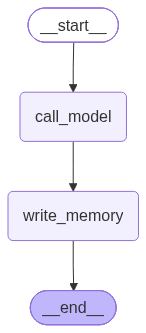

In [3]:
import uuid
from dataclasses import dataclass
from pydantic import BaseModel, Field
from langchain_core.messages import SystemMessage
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.runtime import Runtime
from langgraph.checkpoint.memory import InMemorySaver
from helpers import get_llm

@dataclass
class UserContext:
    user_id: str

class NewMemories(BaseModel):
    facts: list[str] = Field(description="New durable facts about the user (preferences, profile, goals, constraints). Empty list if none.")

extractor = get_llm(effort="low").with_structured_output(NewMemories, method="json_schema")

def call_model(state: MessagesState, runtime: Runtime[UserContext]):
    ns = (runtime.context.user_id, "memories")
    memories = [m.value["fact"] for m in runtime.store.search(ns, limit=50)]
    known = "\n".join(f"- {m}" for m in memories) or "(nothing yet)"
    system = SystemMessage(f"You are a friendly personal assistant. Be brief (max 3 sentences).\n"
                           f"Use what you know about this user:\n{known}")
    return {"messages": [llm.invoke([system] + state["messages"])]}

def write_memory(state: MessagesState, runtime: Runtime[UserContext]):
    ns = (runtime.context.user_id, "memories")
    known = [m.value["fact"] for m in runtime.store.search(ns, limit=50)]
    last_user_msg = next(m for m in reversed(state["messages"]) if m.type == "human").text
    new = extractor.invoke(f"Already known facts: {known}\n\nExtract only NEW long-term facts from this user message:\n{last_user_msg}")
    for fact in new.facts:
        runtime.store.put(ns, str(uuid.uuid4()), {"fact": fact})
    if new.facts:
        print("   🧠 saved:", new.facts)
    return {}

b = StateGraph(MessagesState, context_schema=UserContext)
b.add_node(call_model); b.add_node(write_memory)
b.add_edge(START, "call_model"); b.add_edge("call_model", "write_memory"); b.add_edge("write_memory", END)

memory_store = InMemoryStore()
assistant = b.compile(checkpointer=InMemorySaver(), store=memory_store)
show_graph(assistant)

In [4]:
def chat(text, thread_id, user_id):
    out = assistant.invoke({"messages": [("user", text)]},
                           {"configurable": {"thread_id": thread_id}},
                           context=UserContext(user_id=user_id))
    print(f"🧑 ({user_id}, {thread_id}) {text}\n🤖 {out['messages'][-1].text}\n")

chat("Hi! I'm Meera. I'm vegetarian and allergic to peanuts.", thread_id="monday", user_id="meera")
chat("Also, I'm training for a half marathon in December.", thread_id="monday", user_id="meera")

   🧠 saved: ["User's name is Meera", 'User is vegetarian', 'User is allergic to peanuts']
🧑 (meera, monday) Hi! I'm Meera. I'm vegetarian and allergic to peanuts.
🤖 Hi Meera, nice to meet you! I'll keep in mind that you're vegetarian and allergic to peanuts whenever we talk about food, recipes, or restaurants. What can I help you with today?



   🧠 saved: ['User is training for a half marathon in December']
🧑 (meera, monday) Also, I'm training for a half marathon in December.
🤖 That's exciting, Meera, good luck with your training! I can help with vegetarian, peanut-free meal ideas to fuel your runs, like protein-rich lentil dishes or pre-run snacks. Would you like help with nutrition, a training plan, or something else?



### New thread, same user → memories carry over

In [5]:
chat("Suggest a dinner for tonight.", thread_id="friday", user_id="meera")

🧑 (meera, friday) Suggest a dinner for tonight.
🤖 How about a chickpea and spinach coconut curry over brown rice, Meera? It's vegetarian, peanut-free, and packed with carbs and protein to fuel your half marathon training. Add a side of roasted sweet potatoes if you had a long run today!



### Different user → no access to Meera's memories

In [6]:
chat("Suggest a dinner for tonight.", thread_id="arjun-friday", user_id="arjun")

🧑 (arjun, arjun-friday) Suggest a dinner for tonight.
🤖 How about a **garlic butter salmon with roasted vegetables**? It takes about 25 minutes, and everything cooks on one sheet pan for easy cleanup. If you'd rather something different, tell me your tastes or dietary needs and I'll tailor a suggestion.



In [7]:
for item in memory_store.search(("meera", "memories")):
    print("•", item.value["fact"])

• User's name is Meera
• User is vegetarian
• User is allergic to peanuts
• User is training for a half marathon in December


## 3. Designing memory (cheat-sheet)

| Memory type | Example | Store shape |
|---|---|---|
| **Semantic** (facts) | "vegetarian", "lives in Pune" | collection of docs, or one `profile` doc updated in place |
| **Episodic** (experiences) | past successful conversations | few-shot examples searched by similarity |
| **Procedural** (instructions) | "user prefers bullet points" | an instructions doc the agent can update |

**When to write:** in the hot path (like here: simple, adds latency) or in a background job after the conversation.

## ✅ Recap
* Store = cross-thread memory, organized by namespace tuples.
* `compile(store=...)` + `runtime.store` inside nodes; `context=...` passes per-run config like `user_id`.
* Extract memories with structured output; read them into the system prompt.